# 02 – Exploration & Cleaning
Exploring the merged dataset to spot unusual periods and outliers before analysis.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/bikes_weather_clean.csv", parse_dates=["date"])
print(df.shape)
df.describe().round(1)

(5907, 14)


,date,hires,temp_mean,temp_max,rain_mm,wind_max_kmh,sunshine_hrs,year,month
count,5907,5907.0,5907.0,5907.0,5907.0,5907.0,5907.0,5907.0,5907.0
mean,2018-08-30 00:00:00,26226.5,11.4,15.0,1.9,20.7,7.6,2018.2,6.5
min,2010-07-30 00:00:00,0.0,-6.3,-1.1,0.0,3.5,0.0,2010.0,1.0
25%,2014-08-14 12:00:00,19997.0,7.2,10.3,0.0,14.8,3.9,2014.0,4.0
50%,2018-08-30 00:00:00,26120.0,11.3,14.8,0.2,19.5,7.8,2018.0,7.0
75%,2022-09-14 12:00:00,32160.5,15.7,19.7,2.2,25.4,11.6,2022.0,9.0
max,2026-09-30 00:00:00,73094.0,30.3,38.0,51.6,68.0,16.0,2026.0,12.0
std,NaN,9210.7,5.7,6.3,3.7,7.9,4.7,4.7,3.4


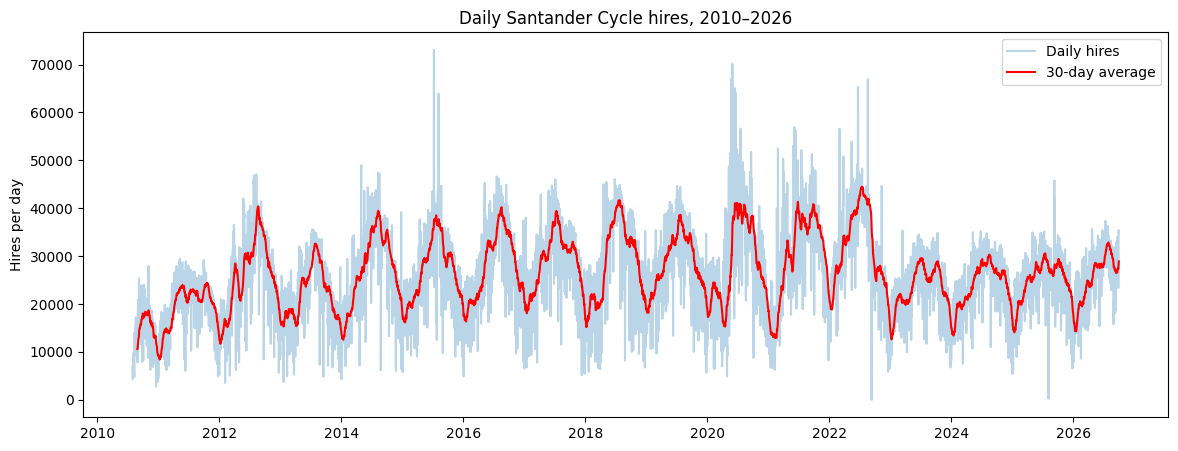

<Figure size 640x480 with 0 Axes>

In [6]:
df["hires_30d_avg"] = df["hires"].rolling(30).mean()

plt.figure(figsize=(14, 5))
plt.plot(df["date"], df["hires"], alpha=0.3, label="Daily hires")
plt.plot(df["date"], df["hires_30d_avg"], color="red", label="30-day average")
plt.title("Daily Santander Cycle hires, 2010–2026")
plt.ylabel("Hires per day")
plt.legend()
plt.show()

plt.savefig("images/daily_hires_2010_2026.png", dpi=150, bbox_inches="tight")

In [3]:
cols = ["date", "day_of_week", "hires", "temp_mean", "rain_mm"]

print("BUSIEST DAYS")
print(df.nlargest(10, "hires")[cols].to_string(index=False))

print("\nQUIETEST DAYS")
print(df.nsmallest(10, "hires")[cols].to_string(index=False))

BUSIEST DAYS
      date day_of_week  hires  temp_mean  rain_mm
2015-07-09    Thursday  73094       15.9      0.0
2020-05-30    Saturday  70170       16.5      0.0
2020-05-25      Monday  67034       17.4      0.0
2022-08-19      Friday  66972       20.0      0.9
2022-06-21     Tuesday  65326       16.5      0.0
2020-06-13    Saturday  65045       17.2      3.7
2020-06-20    Saturday  64041       16.3      0.4
2015-08-06    Thursday  63963       17.7      0.1
2020-05-31      Sunday  63116       17.4      0.0
2020-06-14      Sunday  57516       16.7      1.8

QUIETEST DAYS
      date day_of_week  hires  temp_mean  rain_mm
2022-09-10    Saturday      0       16.4      0.8
2022-09-11      Sunday      0       17.2      0.0
2025-08-05     Tuesday    188       17.1      0.0
2010-12-19      Sunday   2764       -2.6      0.0
2010-12-18    Saturday   2805       -2.3      4.3
2012-02-05      Sunday   3531        0.5      5.7
2013-01-20      Sunday   3728       -1.2      5.0
2010-12-28     Tuesday

## Cleaning decisions
- **Excluded:** system outage days (10–11 Sep 2022 planned upgrade for e-bike launch; 5 Aug 2025 software failure) and 2010 (launch year).
- **Flagged, not removed:** COVID period (23 Mar 2020 – 19 Jul 2021) and known tube strike days – these reflect real but unusual behaviour.

In [4]:
# 1. Flag system outages
outage_dates = pd.to_datetime(["2022-09-10", "2022-09-11", "2025-08-05"])
df["is_outage"] = df["date"].isin(outage_dates)

# 2. Flag COVID period (first lockdown to end of restrictions in England)
df["is_covid"] = df["date"].between("2020-03-23", "2021-07-19")

# 3. Flag tube strike days (found in the busiest-days check)
strike_dates = pd.to_datetime(["2015-07-09", "2015-08-06", "2022-06-21", "2022-08-19"])
df["is_tube_strike"] = df["date"].isin(strike_dates)

# 4. Build the analysis dataset: remove outages and 2010
clean = df[(~df["is_outage"]) & (df["year"] >= 2011)].copy()
clean = clean.drop(columns=["hires_30d_avg"])

print("Before:", len(df), "rows | After:", len(clean), "rows")
print("COVID days flagged:", clean["is_covid"].sum())
print("Strike days flagged:", clean["is_tube_strike"].sum())

clean.to_csv("data/bikes_analysis_ready.csv", index=False)
print("Saved bikes_analysis_ready.csv")

Before: 5907 rows | After: 5749 rows
COVID days flagged: 484
Strike days flagged: 4
Saved bikes_analysis_ready.csv
